# Détection d'une figure : du simulateur à l'entraînement
Dataset synthétique → apprentissage → feature maps → prédiction + NMS.

In [12]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

from src.dataset_generator_2 import make_example
from src.detector import Detector, STRIDE, CLASSES, predict_class
from src.visualize import show_images, show_feature_maps, show_detections
from src.detector import code
from src.train import evaluate, train

MODEL_SIZE = 64          # taille d'entrée utilisée à l'entraînement
assert MODEL_SIZE % STRIDE == 0   # la grille de feature maps fait MODEL_SIZE // STRIDE

## 1. Génération du dataset
On génère directement les images à la taille attendue par le modèle.

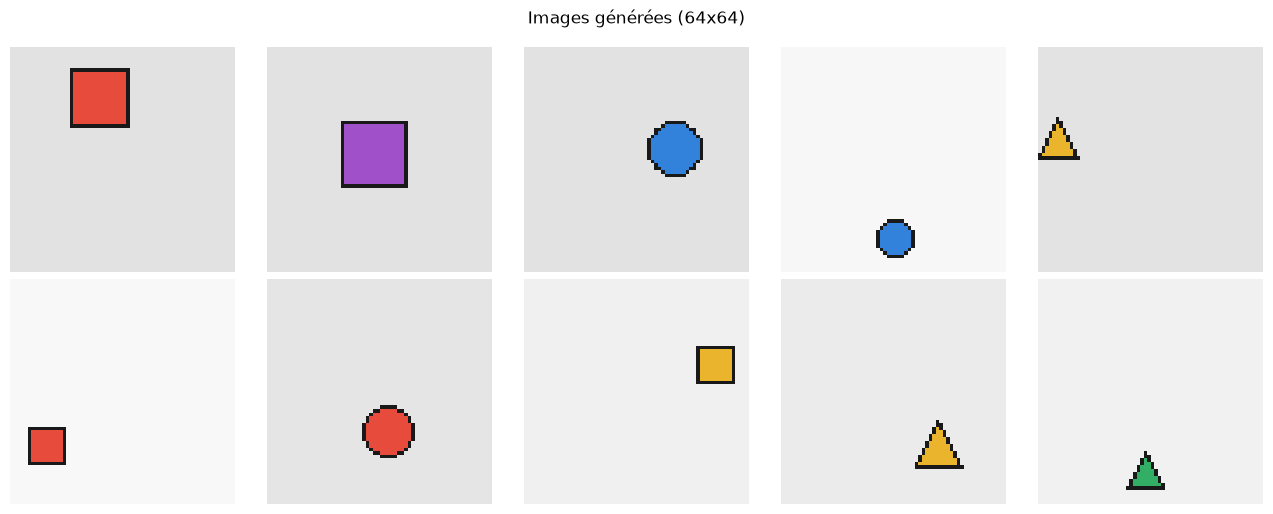

In [13]:
rng = random.Random(123)
pil_images = [make_example(MODEL_SIZE, rng)[0] for _ in range(10)]
show_images(pil_images, f"Images générées ({MODEL_SIZE}x{MODEL_SIZE})")

Les images sont déjà générées à la taille attendue par le détecteur (`MODEL_SIZE`×`MODEL_SIZE`, multiple du stride) : aucun redimensionnement, on les convertit simplement en tenseurs `(3, H, W)` normalisés dans [0, 1].

In [14]:
def to_tensor(image):
    return torch.from_numpy(np.asarray(image.convert("RGB"), dtype=np.float32).copy()).permute(2, 0, 1) / 255.0

images = torch.stack([to_tensor(im) for im in pil_images])
print(images.shape)

torch.Size([10, 3, 64, 64])


## 2. Génération d'un jeu de données d'entraînement plus grand
On génère 200 images pour l'entraînement et 40 images indépendantes pour la validation. Les étiquettes (en pixels) sont encodées en cibles `(5, G, G)`.

In [15]:
def make_dataset(count, seed):
    rng = random.Random(seed)
    dataset_images, targets = [], []
    for _ in range(count):
        image, label = make_example(MODEL_SIZE, rng)
        cx, cy, width, height, class_id = map(float, label.split())
        dataset_images.append(to_tensor(image))
        targets.append(code(cx, cy, width, height, int(class_id), size=MODEL_SIZE))
    return TensorDataset(torch.stack(dataset_images), torch.stack(targets))

## 3. Entraînement du modèle


In [16]:
TRAIN_SAMPLES = 2000
VAL_SAMPLES = 400
BATCH_SIZE = 64
EPOCHS = 50

import tempfile
from datetime import datetime
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

# Les logs sont écrits hors du dossier synchronisé ownCloud (TensorBoard/TensorFlow
# n'y accède pas correctement : "runs/demo is not a directory").
LOG_ROOT = Path(tempfile.gettempdir()) / "tb_runs" / "demo"
LOG_ROOT.mkdir(parents=True, exist_ok=True)
print("Logs TensorBoard :", LOG_ROOT)

torch.manual_seed(0)
train_set = make_dataset(TRAIN_SAMPLES, seed=7)
val_set = make_dataset(VAL_SAMPLES, seed=8)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)

model = Detector()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
run_dir = LOG_ROOT / datetime.now().strftime('%Y%m%d-%H%M%S')
with SummaryWriter(log_dir=str(run_dir)) as writer:
         for epoch in range(1, EPOCHS + 1):
          mean_loss = train(model, train_loader, optimizer)
          val_iou, val_accuracy, val_class_acc = evaluate(model, val_loader, MODEL_SIZE)
          writer.add_scalar("Loss/train", mean_loss, epoch)
          writer.add_scalar("IoU/validation", val_iou, epoch)
          writer.add_scalar("Accuracy/validation_IoU_gt_0.5", val_accuracy, epoch)
          writer.add_scalar("Accuracy/validation_classe", val_class_acc, epoch)
          print(f"epoch {epoch:2d}  loss {mean_loss:.4f}  "
                f"val IoU {val_iou:.3f}  IoU>0.5 {val_accuracy:.0%}  classe {val_class_acc:.0%}")

model.eval();

Logs TensorBoard : C:\Users\acer\AppData\Local\Temp\tb_runs\demo
epoch  1  loss 0.0285  val IoU 0.417  IoU>0.5 28%  classe 52%
epoch  2  loss 0.0141  val IoU 0.551  IoU>0.5 62%  classe 80%
epoch  3  loss 0.0079  val IoU 0.599  IoU>0.5 70%  classe 92%
epoch  4  loss 0.0050  val IoU 0.629  IoU>0.5 77%  classe 96%
epoch  5  loss 0.0038  val IoU 0.646  IoU>0.5 82%  classe 96%
epoch  6  loss 0.0032  val IoU 0.667  IoU>0.5 87%  classe 98%
epoch  7  loss 0.0028  val IoU 0.676  IoU>0.5 86%  classe 96%
epoch  8  loss 0.0026  val IoU 0.685  IoU>0.5 86%  classe 99%
epoch  9  loss 0.0023  val IoU 0.693  IoU>0.5 88%  classe 100%
epoch 10  loss 0.0021  val IoU 0.682  IoU>0.5 87%  classe 99%
epoch 11  loss 0.0020  val IoU 0.712  IoU>0.5 93%  classe 99%
epoch 12  loss 0.0018  val IoU 0.717  IoU>0.5 93%  classe 100%
epoch 13  loss 0.0017  val IoU 0.700  IoU>0.5 87%  classe 100%
epoch 14  loss 0.0017  val IoU 0.723  IoU>0.5 93%  classe 100%
epoch 15  loss 0.0016  val IoU 0.715  IoU>0.5 90%  classe 100%


In [20]:
# Affiche la commande à lancer dans un terminal pour ouvrir TensorBoard dans le navigateur
import sys
print(f'& "{sys.executable}" -m tensorboard.main --logdir "{LOG_ROOT}" --port 6006')
print("Puis ouvrir http://localhost:6006")

& "c:\Users\acer\Downloads\optionB\sujet_tensorboard\tpml\Scripts\python.exe" -m tensorboard.main --logdir "C:\Users\acer\AppData\Local\Temp\tb_runs\demo" --port 6006
Puis ouvrir http://localhost:6006


## 4. Feature maps

torch.Size([10, 32, 8, 8])


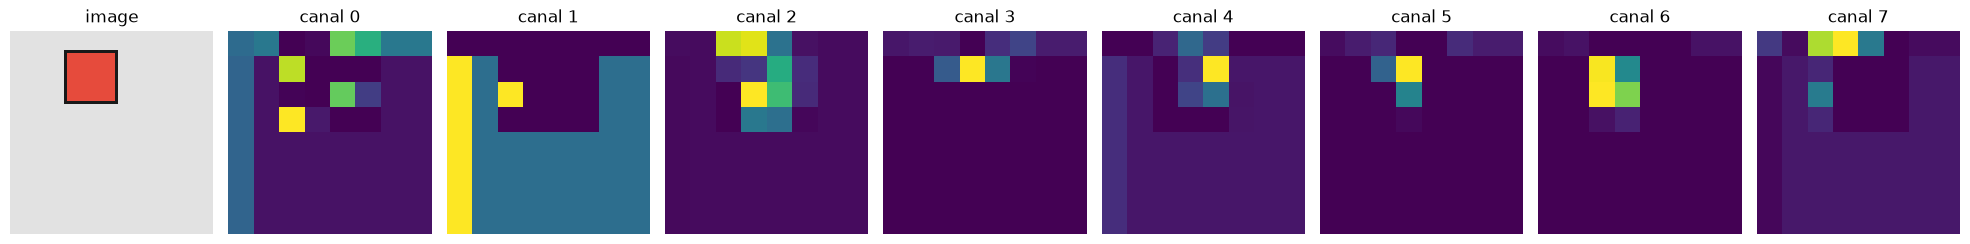

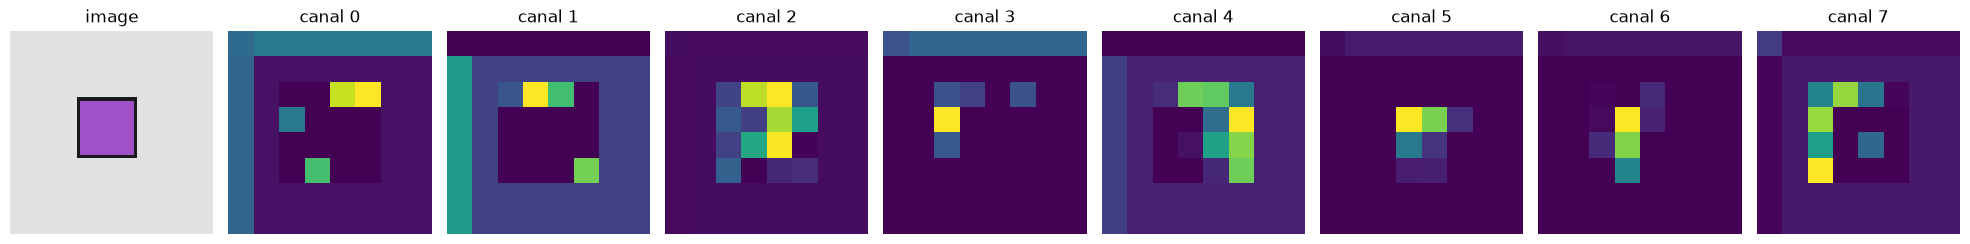

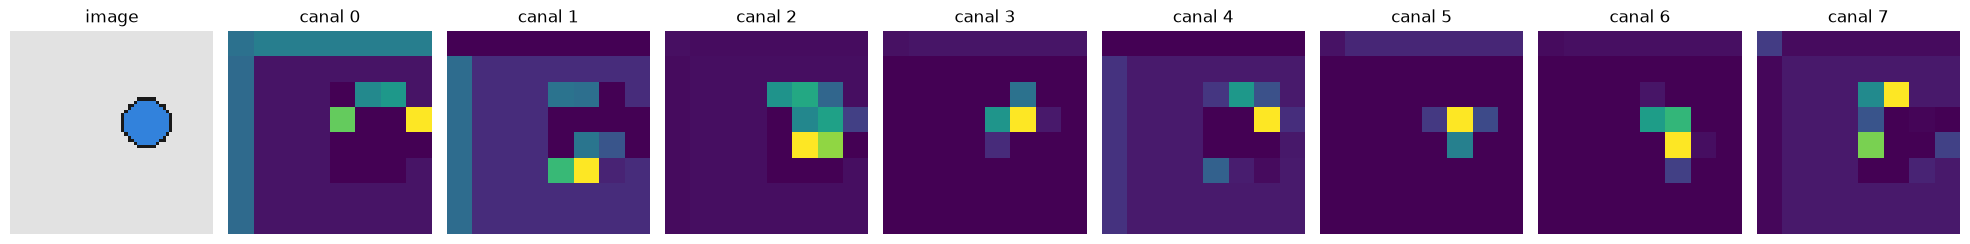

tensor([[ 0.1671,  0.1390, -0.1398],
        [ 0.1220,  0.0261, -0.0821],
        [-0.0867, -0.0966, -0.1638]], grad_fn=<SelectBackward0>)


In [21]:
with torch.no_grad():
    maps = model.feature_maps(images)   # (N, 32, 8, 8)
print(maps.shape)
for i in range(3):
    show_feature_maps(images[i], maps[i], n_maps=8)

print(model.backbone[0].weight[3, 0, :, :])

## 5. Prédiction, décodage et NMS : une boîte par image

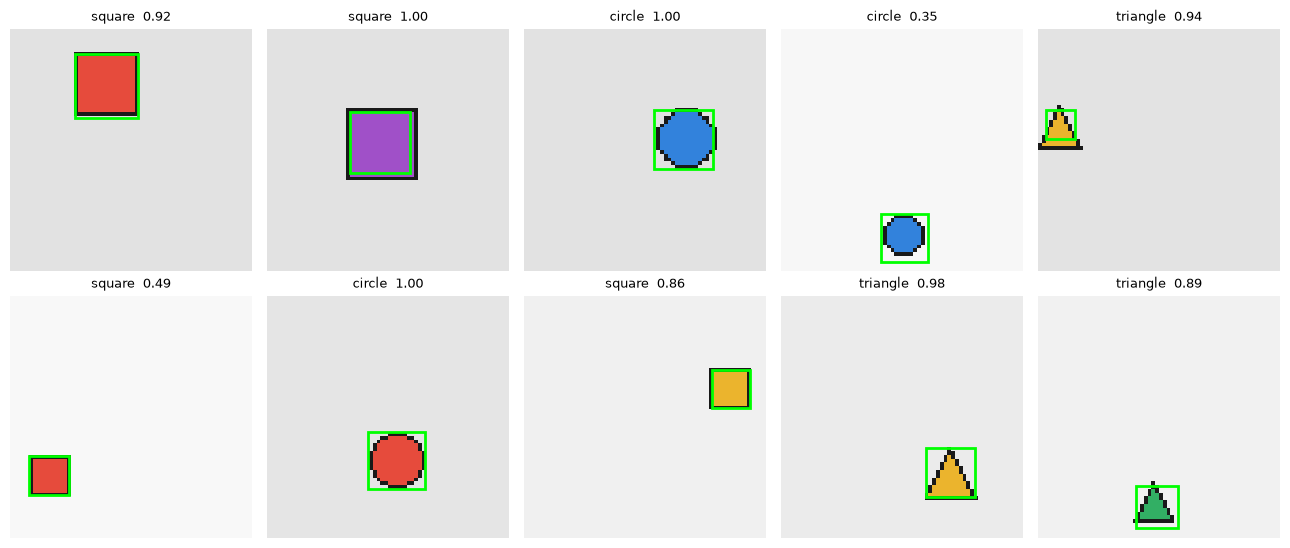

In [22]:
with torch.no_grad():
    logits = model(images)
results = [predict_class(l, MODEL_SIZE) for l in logits]
labels = [CLASSES[c] for _, _, c in results]
show_detections(list(images), [b for b, _, _ in results], [s for _, s, _ in results], labels=labels)

In [23]:
from src.detector import iou, predict_class, NUM_CLASSES

model.eval()
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)   # lignes = vraie classe, colonnes = classe prédite
iou_par_classe = {c: [] for c in range(NUM_CLASSES)}

with torch.no_grad():
    for images_batch, targets in val_loader:
        logits = model(images_batch)
        grid = targets.shape[-1]
        for logit, target in zip(logits, targets):
            box, _, pred_class = predict_class(logit, MODEL_SIZE)
            row, col = divmod(int(target[0].argmax()), grid)
            _, dx, dy, w, h = target[:5, row, col].tolist()
            true_class = int(target[5:, row, col].argmax())
            cx, cy = (col + dx) * MODEL_SIZE / grid, (row + dy) * MODEL_SIZE / grid
            truth = torch.tensor([cx - w * MODEL_SIZE / 2, cy - h * MODEL_SIZE / 2,
                                  cx + w * MODEL_SIZE / 2, cy + h * MODEL_SIZE / 2])
            confusion[true_class, pred_class] += 1
            iou_par_classe[true_class].append(float(iou(box, truth[None])[0]))

print("Matrice de confusion (lignes = vraie classe, colonnes = classe prédite)")
print(" " * 12, *[f"{name:>9}" for name in CLASSES])
for i, name in enumerate(CLASSES):
    print(f"{name:>12}", *[f"{v:>9}" for v in confusion[i]])
print()
for c, name in enumerate(CLASSES):
    print(f"IoU moyen pour {name} : {np.mean(iou_par_classe[c]):.3f}")

Matrice de confusion (lignes = vraie classe, colonnes = classe prédite)
                circle    square  triangle
      circle       121         0         1
      square         3       132         0
    triangle         0         0       143

IoU moyen pour circle : 0.825
IoU moyen pour square : 0.717
IoU moyen pour triangle : 0.733


circle


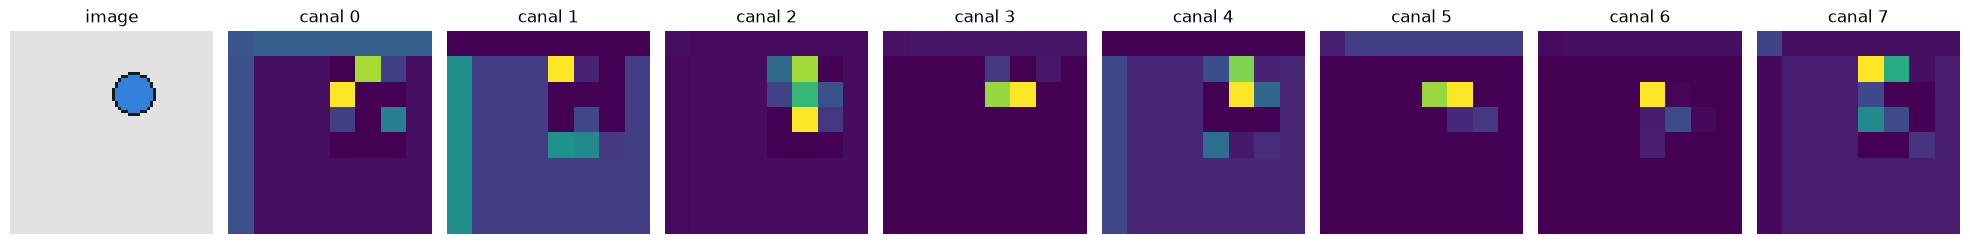

square


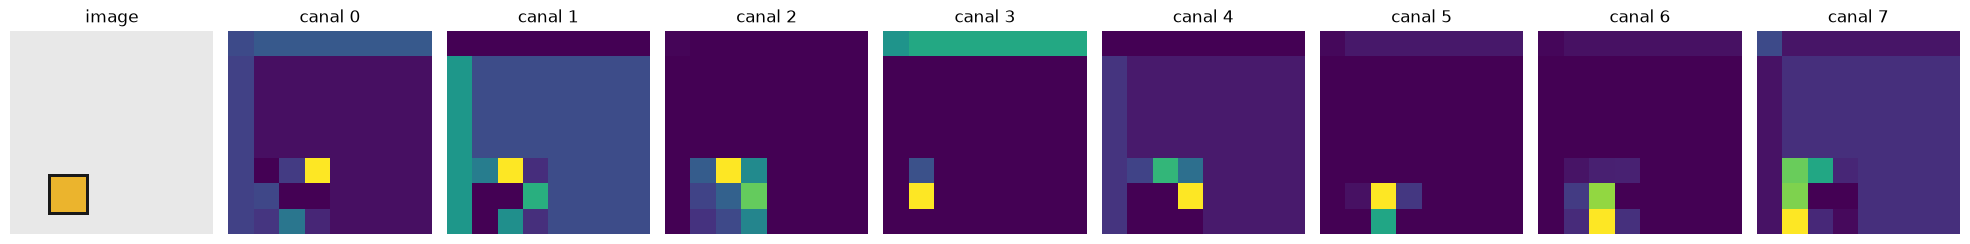

triangle


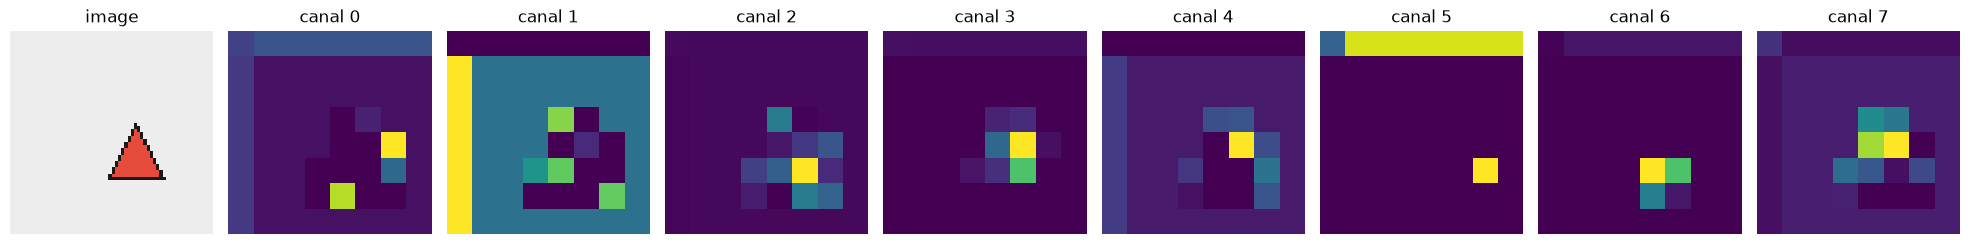

In [24]:
from src.detector import NUM_CLASSES

# Une image de validation pour chaque forme
exemples = {}
for image, target in val_set:
    row, col = divmod(int(target[0].argmax()), target.shape[-1])
    classe = int(target[5:, row, col].argmax())
    if classe not in exemples:
        exemples[classe] = image
    if len(exemples) == NUM_CLASSES:
        break

model.eval()
for classe in sorted(exemples):
    print(CLASSES[classe])
    with torch.no_grad():
        maps = model.feature_maps(exemples[classe][None])[0]   # (32, 8, 8)
    show_feature_maps(exemples[classe], maps, n_maps=8)